# DreamerV3 Close-Gap Run Toward the 98% BO Target

This notebook launches a fresh DreamerV3 run from scratch in a new log directory and uses a stronger exploit-oriented schedule than the earlier elite-replay notebook.

The intervention has three parts:

- bias replay toward elites from the start with a 128 elite / 64 recent split
- run a short low-entropy fine-tuning phase once the policy has discovered strong regions
- optionally finish with a final squeeze phase that reduces action noise even further if the BO gap remains open

The goal is not just to touch the target once, but to make the evaluation policy as close as possible to the BO benchmark.

In [1]:
from __future__ import annotations

import copy
import importlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

import dreamerv3_haberbosch_helpers as dreamer_helpers

hb = importlib.reload(dreamer_helpers)
hb.set_plot_style()

WORKSPACE_DIR = hb.WORKSPACE_DIR
RUN_LOGDIR = WORKSPACE_DIR / 'runs' / 'dreamerv3_haber_bosch_target95_elite_replay_close_gap'
SEED = 7

In [2]:
BO_REFERENCE = {
    'reward': 2712.651793,
    'normalized_action': np.array([
        -0.6127335418989747,
        0.08136597881754437,
        0.6577094487733803,
        1.0,
        1.0,
        1.0,
        -1.0,
    ], dtype=np.float32),
}

TARGET_FRACTION = 0.98
TARGET_REWARD = TARGET_FRACTION * BO_REFERENCE['reward']

DISCOVERY_END = 1300
EXPLOIT_END = 1500
SQUEEZE_END = 1600

DISCOVERY_BLOCK = 100
EXPLOIT_BLOCK = 50
SQUEEZE_BLOCK = 25

CONVERGENCE_WINDOW = 50
EVAL_STABILITY_WINDOW = 3
REPLAY_SIZE = 192
RUN_SQUEEZE_PHASE = True

pd.DataFrame([
    {
        'bo_reward': BO_REFERENCE['reward'],
        'target_fraction': TARGET_FRACTION,
        'target_reward': TARGET_REWARD,
        'discovery_end': DISCOVERY_END,
        'exploit_end': EXPLOIT_END,
        'squeeze_end': SQUEEZE_END,
        'replay_size': REPLAY_SIZE,
        'run_logdir': str(RUN_LOGDIR),
    }
])

,bo_reward,target_fraction,target_reward,discovery_end,exploit_end,squeeze_end,replay_size,run_logdir
0,2712.651793,0.98,2658.398757,1300,1500,1600,192,/Users/campatzis/Documents/Research/runs/dream...


In [3]:
def evaluate_normalized_action(environment, action: np.ndarray) -> dict[str, float]:
    environment.reset()
    _, reward, terminated, truncated, info = environment.step(action)
    row = {
        'reward': float(reward),
        'terminated': bool(terminated),
        'truncated': bool(truncated),
    }
    scaled = np.asarray(info.get('scaled_action', np.zeros_like(action)), dtype=np.float64)
    row.update({f'a{index}': float(action[index - 1]) for index in range(1, 8)})
    row.update({f'a{index}_physical': float(scaled[index - 1]) for index in range(1, 8)})
    for name, value in info.items():
        if name == 'scaled_action':
            continue
        if isinstance(value, (int, float, np.integer, np.floating, bool)):
            row[name] = float(value) if not isinstance(value, bool) else bool(value)
    return row

preflight = hb.build_preflight_frame()
display(preflight)
if not preflight['ok'].all():
    missing = preflight.loc[~preflight['ok'], 'item'].tolist()
    raise RuntimeError(f'Preflight failed for: {missing}')

env = hb.make_haber_bosch_env()
try:
    smoke_test = hb.run_smoke_test(env)
    bo_reference_row = evaluate_normalized_action(env, BO_REFERENCE['normalized_action'])
finally:
    env.close()

display(smoke_test.to_frame(name='value'))
baseline_frame = pd.DataFrame([bo_reference_row])
baseline_frame['target_reward'] = TARGET_REWARD
baseline_frame['target_gap'] = baseline_frame['target_reward'] - baseline_frame['reward']
display(
    baseline_frame[[
        'reward',
        'target_reward',
        'target_gap',
        'nh3_kg_per_s',
        'power_kw',
        'revenue_per_h',
        'energy_cost_per_h',
    ]]
)

,item,value,ok
0,Workspace,/Users/campatzis/Documents/Research,True
1,Flowsheet,/Users/campatzis/Documents/Research/DWSIM Simu...,True
2,Bridge Script,/Users/campatzis/Documents/Research/.dwsim_sup...,True
3,Rosetta Wrapper,/Users/campatzis/Documents/Research/.venv311-r...,True
4,Rosetta Python,/Users/campatzis/Documents/Research/.venv311-r...,True
5,Mono Root,/Users/campatzis/Documents/Research/.mono-runt...,True
6,DWSIM Automation Dir,/Applications/DWSIM.app/Contents/MonoBundle,True
7,Notebook Kernel Architecture,arm64,True


,value
baseline_observation,"[0.0, 0.0, 0.0, 0.0, 0.0]"
step_observation,"[1.9237689962789544, 2448.9456451678902, 425.0..."
reward,737.350075
terminated,False
truncated,False
info,"{'nh3_kg_per_s': 1.9237689962789544, 'nh3_ton_..."


,reward,target_reward,target_gap,nh3_kg_per_s,power_kw,revenue_per_h,energy_cost_per_h
0,2712.651793,2658.398757,-54.253036,2.4751,2814.232893,4455.180451,1742.528658


## Strategy

The earlier elite-replay run already showed that Dreamer can discover target-level policies, but it still missed the notebook convergence rule because the sampled training distribution remained too noisy.

This follow-up notebook changes the schedule rather than the reward:

- **Discovery phase:** keep the stronger 128 elite / 64 recent replay mix from the start and modestly increase the train ratio so good episodes are reused more aggressively.
- **Exploit phase:** cut actor entropy sharply and lower the actor `min_std` floor so the policy stops wasting reward on avoidable action noise.
- **Squeeze phase:** if the BO gap is still open, move replay even further toward elites and remove the remaining entropy pressure for a short final push.

The important additional optimization here is the lower `min_std` during fine-tuning. In this single-step continuous action problem, a high exploration floor can keep the training policy below the BO neighborhood even after the model has already learned where the good actions live.

In [4]:
def count_completed_episodes(logdir: Path) -> int:
    train_eps = Path(logdir) / 'train_eps'
    return sum(1 for _ in train_eps.glob('*.npz')) if train_eps.exists() else 0

def load_train_metrics(logdir: Path) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    metrics = hb.load_metrics_frame(logdir)
    train = metrics.loc[metrics['train_return'].notna()].copy()
    train = train.sort_values('step').reset_index(drop=True)
    evals = metrics.loc[metrics['eval_return'].notna()].copy()
    evals = evals.sort_values('step').reset_index(drop=True)
    return metrics, train, evals

def summarize_target_progress(train_df: pd.DataFrame, target_reward: float, window: int) -> tuple[dict[str, float | int | bool], pd.DataFrame]:
    if train_df.empty:
        empty_summary = {
            'episodes': 0,
            'best_train_reward': float('nan'),
            'gap_to_target': float('nan'),
            'latest_reward': float('nan'),
            'rolling_mean': float('nan'),
            'rolling_hit_rate': float('nan'),
            'target_hits': 0,
            'converged': False,
        }
        return empty_summary, train_df.copy()

    summary_frame = train_df.copy()
    summary_frame['target_hit'] = summary_frame['train_return'] >= target_reward
    summary_frame['rolling_mean'] = summary_frame['train_return'].rolling(window, min_periods=1).mean()
    summary_frame['rolling_hit_rate'] = summary_frame['target_hit'].rolling(window, min_periods=1).mean()

    best_row = summary_frame.loc[int(summary_frame['train_return'].idxmax())].copy()
    last_row = summary_frame.iloc[-1].copy()
    summary = {
        'episodes': int(len(summary_frame)),
        'best_train_reward': float(best_row['train_return']),
        'gap_to_target': float(target_reward - best_row['train_return']),
        'latest_reward': float(last_row['train_return']),
        'rolling_mean': float(last_row['rolling_mean']),
        'rolling_hit_rate': float(last_row['rolling_hit_rate']),
        'target_hits': int(summary_frame['target_hit'].sum()),
        'converged': bool(last_row['rolling_mean'] >= target_reward),
    }
    return summary, summary_frame

def summarize_eval_progress(eval_df: pd.DataFrame, target_reward: float, window: int) -> tuple[dict[str, float | int | bool], pd.DataFrame]:
    if eval_df.empty:
        empty_summary = {
            'eval_points': 0,
            'best_eval_return': float('nan'),
            'best_eval_gap': float('nan'),
            'latest_eval_return': float('nan'),
            'latest_eval_gap': float('nan'),
            'mean_last_eval': float('nan'),
            'eval_target_hits': 0,
            'stable_eval_target': False,
        }
        return empty_summary, eval_df.copy()

    summary_frame = eval_df.copy()
    summary_frame['target_hit'] = summary_frame['eval_return'] >= target_reward
    summary_frame['tail_mean'] = summary_frame['eval_return'].rolling(window, min_periods=1).mean()

    best_row = summary_frame.loc[int(summary_frame['eval_return'].idxmax())].copy()
    last_row = summary_frame.iloc[-1].copy()
    summary = {
        'eval_points': int(len(summary_frame)),
        'best_eval_return': float(best_row['eval_return']),
        'best_eval_gap': float(target_reward - best_row['eval_return']),
        'latest_eval_return': float(last_row['eval_return']),
        'latest_eval_gap': float(target_reward - last_row['eval_return']),
        'mean_last_eval': float(last_row['tail_mean']),
        'eval_target_hits': int(summary_frame['target_hit'].sum()),
        'stable_eval_target': bool(last_row['tail_mean'] >= target_reward and best_row['eval_return'] >= target_reward),
    }
    return summary, summary_frame

def summarize_replay_selection(logdir: Path, config: hb.DreamerExperimentConfig, target_reward: float) -> tuple[pd.DataFrame, pd.DataFrame]:
    replay_frame = hb.inspect_replay_inventory(logdir / 'train_eps', config, target_reward=target_reward)
    selected = replay_frame.loc[replay_frame['selected_for_replay']].copy()
    return replay_frame, selected

def build_base_config(logdir: Path) -> hb.DreamerExperimentConfig:
    cfg = hb.DreamerExperimentConfig()
    cfg.seed = SEED
    cfg.logdir = logdir
    cfg.seed_logdir_from = None
    cfg.resume_from_checkpoint = None
    cfg.reset_existing_run = True
    cfg.target_episodes = DISCOVERY_BLOCK
    cfg.prefill_steps = 64
    cfg.replay_size = REPLAY_SIZE
    cfg.replay_policy = 'elite_recent'
    cfg.replay_keep_top_episodes = 128
    cfg.replay_keep_recent_episodes = 64
    cfg.eval_every_steps = DISCOVERY_BLOCK
    cfg.log_every_steps = 25
    cfg.eval_episodes = 5
    cfg.train_ratio = 14.0
    cfg.episode_report_frequency = 10
    cfg.dreamer_overrides = {}
    return cfg

def build_phase_config(base_config: hb.DreamerExperimentConfig, phase_spec: dict[str, object], *, reset_existing_run: bool) -> hb.DreamerExperimentConfig:
    cfg = copy.deepcopy(base_config)
    cfg.target_episodes = int(phase_spec['target_episodes'])
    cfg.reset_existing_run = bool(reset_existing_run)
    cfg.replay_size = int(phase_spec['replay_keep_top']) + int(phase_spec['replay_keep_recent'])
    cfg.replay_policy = 'elite_recent'
    cfg.replay_keep_top_episodes = int(phase_spec['replay_keep_top'])
    cfg.replay_keep_recent_episodes = int(phase_spec['replay_keep_recent'])
    cfg.eval_every_steps = int(phase_spec['eval_every_steps'])
    cfg.log_every_steps = int(phase_spec['log_every_steps'])
    cfg.eval_episodes = int(phase_spec['eval_episodes'])
    cfg.train_ratio = float(phase_spec['train_ratio'])
    cfg.episode_report_frequency = int(phase_spec['episode_report_frequency'])
    cfg.dreamer_overrides = copy.deepcopy(phase_spec['dreamer_overrides'])
    return cfg

def phase_plan_frame(phase_specs: list[dict[str, object]]) -> pd.DataFrame:
    rows = []
    for spec in phase_specs:
        actor_cfg = spec['dreamer_overrides']['actor']
        rows.append(
            {
                'phase': spec['name'],
                'target_episodes': int(spec['target_episodes']),
                'block_size': int(spec['block_size']),
                'replay_keep_top': int(spec['replay_keep_top']),
                'replay_keep_recent': int(spec['replay_keep_recent']),
                'train_ratio': float(spec['train_ratio']),
                'eval_every_steps': int(spec['eval_every_steps']),
                'eval_episodes': int(spec['eval_episodes']),
                'actor_entropy': float(actor_cfg['entropy']),
                'actor_min_std': float(actor_cfg['min_std']),
                'eval_state_mean': bool(spec['dreamer_overrides']['eval_state_mean']),
            }
        )
    return pd.DataFrame(rows)

def compare_run_to_target(logdir: Path, target_reward: float) -> dict[str, float | int | bool | str]:
    metrics_path = Path(logdir) / 'metrics.jsonl'
    if not metrics_path.exists():
        return {
            'logdir': str(logdir),
            'status': 'missing',
        }
    metrics_df, train_df, eval_df = load_train_metrics(logdir)
    train_summary, _ = summarize_target_progress(train_df, target_reward, CONVERGENCE_WINDOW)
    eval_summary, _ = summarize_eval_progress(eval_df, target_reward, EVAL_STABILITY_WINDOW)
    return {
        'logdir': str(logdir),
        'status': 'ok',
        'episodes': int(train_summary['episodes']),
        'best_train_reward': float(train_summary['best_train_reward']),
        'rolling_mean': float(train_summary['rolling_mean']),
        'best_eval_return': float(eval_summary['best_eval_return']),
        'latest_eval_return': float(eval_summary['latest_eval_return']),
        'mean_last_eval': float(eval_summary['mean_last_eval']),
        'best_eval_gap': float(eval_summary['best_eval_gap']),
        'stable_eval_target': bool(eval_summary['stable_eval_target']),
    }

In [5]:
BASE_CFG = build_base_config(RUN_LOGDIR)

PHASE_SPECS = [
    {
        'name': 'discovery_elite_bias',
        'target_episodes': DISCOVERY_END,
        'block_size': DISCOVERY_BLOCK,
        'replay_keep_top': 128,
        'replay_keep_recent': 64,
        'train_ratio': 14.0,
        'eval_every_steps': 100,
        'log_every_steps': 25,
        'eval_episodes': 5,
        'episode_report_frequency': 10,
        'dreamer_overrides': {
            'actor': {
                'entropy': 1e-4,
                'min_std': 0.05,
            },
            'eval_state_mean': False,
        },
    },
    {
        'name': 'exploit_finetune',
        'target_episodes': EXPLOIT_END,
        'block_size': EXPLOIT_BLOCK,
        'replay_keep_top': 128,
        'replay_keep_recent': 64,
        'train_ratio': 16.0,
        'eval_every_steps': 50,
        'log_every_steps': 25,
        'eval_episodes': 10,
        'episode_report_frequency': 10,
        'dreamer_overrides': {
            'actor': {
                'entropy': 1e-5,
                'min_std': 0.02,
            },
            'eval_state_mean': True,
        },
    },
]

if RUN_SQUEEZE_PHASE:
    PHASE_SPECS.append(
        {
            'name': 'target_squeeze',
            'target_episodes': SQUEEZE_END,
            'block_size': SQUEEZE_BLOCK,
            'replay_keep_top': 160,
            'replay_keep_recent': 32,
            'train_ratio': 18.0,
            'eval_every_steps': 25,
            'log_every_steps': 25,
            'eval_episodes': 10,
            'episode_report_frequency': 10,
            'dreamer_overrides': {
                'actor': {
                    'entropy': 0.0,
                    'min_std': 0.01,
                },
                'eval_state_mean': True,
            },
        }
    )

display(phase_plan_frame(PHASE_SPECS))
objective_text = (
    f'**Objective:** reach or exceed **{TARGET_REWARD:.3f}** with a stable evaluation policy while keeping the run fully reproducible from scratch in a new logdir.'
)
display(Markdown(objective_text))

,phase,target_episodes,block_size,replay_keep_top,replay_keep_recent,train_ratio,eval_every_steps,eval_episodes,actor_entropy,actor_min_std,eval_state_mean
0,discovery_elite_bias,1300,100,128,64,14.0,100,5,0.00010,0.05,False
1,exploit_finetune,1500,50,128,64,16.0,50,10,0.00001,0.02,True
2,target_squeeze,1600,25,160,32,18.0,25,10,0.00000,0.01,True


**Objective:** reach or exceed **2658.399** with a stable evaluation policy while keeping the run fully reproducible from scratch in a new logdir.

In [6]:
RUN_QUICK_VALIDATION = False

if RUN_QUICK_VALIDATION:
    quick_cfg = hb.build_quick_validation_config(
        build_phase_config(BASE_CFG, PHASE_SPECS[0], reset_existing_run=True)
    )
    quick_result = hb.run_dreamer_training(quick_cfg, run_training=True)
    quick_metrics, quick_train, quick_eval = load_train_metrics(quick_cfg.logdir)
    quick_train_summary, _ = summarize_target_progress(quick_train, TARGET_REWARD, window=12)
    quick_eval_summary, _ = summarize_eval_progress(quick_eval, TARGET_REWARD, window=2)
    display(pd.DataFrame([quick_result.get('after', quick_result)]))
    display(pd.DataFrame([{**quick_train_summary, **quick_eval_summary}]))
    hb.plot_training_diagnostics(quick_metrics)
else:
    print('Set RUN_QUICK_VALIDATION = True if you want a cheap end-to-end check before the full run.')

Set RUN_QUICK_VALIDATION = True if you want a cheap end-to-end check before the full run.


## Multi-Phase Training Loop

The loop below runs the full close-gap plan from scratch. It reuses the same log directory across phases, tightens the actor distribution over time, and stops early if the evaluation policy becomes stably target-meeting over the last few eval checkpoints.

In [ ]:
RUN_FRESH_PLAN = True
STOP_ON_STABLE_EVAL_TARGET = True

phase_history: list[dict[str, float | int | bool | str]] = []
LAST_PHASE_NAME: str | None = None
initial_completed_episodes = count_completed_episodes(BASE_CFG.logdir)

if RUN_FRESH_PLAN:
    stop_plan = False

    for phase_index, phase_spec in enumerate(PHASE_SPECS):
        phase_name = str(phase_spec['name'])
        phase_cfg = build_phase_config(
            BASE_CFG,
            phase_spec,
            reset_existing_run=bool(phase_index == 0 and initial_completed_episodes == 0),
        )
        LAST_PHASE_NAME = phase_name
        block_size = int(phase_spec['block_size'])

        if phase_index == 0:
            completed_before_phase = initial_completed_episodes
        else:
            completed_before_phase = count_completed_episodes(phase_cfg.logdir)

        if completed_before_phase >= phase_cfg.target_episodes:
            print(f'Skipping {phase_name}: current logdir already has {completed_before_phase} episodes.')
            continue

        first_block_target = max(((completed_before_phase // block_size) + 1) * block_size, block_size)

        actor_entropy = float(phase_cfg.dreamer_overrides['actor']['entropy'])
        actor_min_std = float(phase_cfg.dreamer_overrides['actor']['min_std'])
        eval_state_mean = bool(phase_cfg.dreamer_overrides['eval_state_mean'])
        print(
            f'Phase {phase_name}: train to {phase_cfg.target_episodes} episodes | '
            f'replay {phase_cfg.replay_keep_top_episodes}+{phase_cfg.replay_keep_recent_episodes} | '
            f'train_ratio {phase_cfg.train_ratio:.1f} | '
            f'entropy {actor_entropy:.1e} | '
            f'min_std {actor_min_std:.2f} | '
            f'eval_state_mean {eval_state_mean}'
        )

        for block_target in range(first_block_target, phase_cfg.target_episodes + 1, block_size):
            phase_cfg.target_episodes = int(block_target)
            phase_cfg.reset_existing_run = bool(
                phase_index == 0
                and completed_before_phase == 0
                and block_target == first_block_target
            )

            result = hb.run_dreamer_training(phase_cfg, run_training=True)
            metrics_df, train_df, eval_df = load_train_metrics(phase_cfg.logdir)
            train_summary, train_df = summarize_target_progress(train_df, TARGET_REWARD, CONVERGENCE_WINDOW)
            eval_summary, eval_df = summarize_eval_progress(eval_df, TARGET_REWARD, EVAL_STABILITY_WINDOW)
            replay_frame, replay_selected = summarize_replay_selection(phase_cfg.logdir, phase_cfg, TARGET_REWARD)

            row = {
                'phase': phase_name,
                'episode_budget': int(block_target),
                'completed_episodes': int(train_summary['episodes']),
                'best_train_reward': float(train_summary['best_train_reward']),
                'rolling_mean': float(train_summary['rolling_mean']),
                'target_hits': int(train_summary['target_hits']),
                'best_eval_return': float(eval_summary['best_eval_return']),
                'best_eval_gap': float(eval_summary['best_eval_gap']),
                'latest_eval_return': float(eval_summary['latest_eval_return']),
                'mean_last_eval': float(eval_summary['mean_last_eval']),
                'stable_eval_target': bool(eval_summary['stable_eval_target']),
                'selected_replay_rows': int(len(replay_selected)),
                'selected_replay_target_hits': int(replay_selected['meets_target'].fillna(False).sum()) if not replay_selected.empty else 0,
                'selected_replay_best_reward': float(replay_selected['reward'].max()) if not replay_selected.empty else float('nan'),
            }
            phase_history.append(row)
            display(pd.DataFrame([row]))

            if STOP_ON_STABLE_EVAL_TARGET and row['stable_eval_target']:
                mean_last_eval = float(row['mean_last_eval'])
                message = (
                    f'Stopping early: the last {EVAL_STABILITY_WINDOW} eval checkpoints average '
                    f'{mean_last_eval:.3f}, which is at or above the 95% BO target {TARGET_REWARD:.3f}.'
                )
                print(message)
                stop_plan = True
                break

        if stop_plan:
            break
else:
    print('Set RUN_FRESH_PLAN = True to archive any prior run in this logdir and execute the full close-gap schedule from scratch.')

Phase discovery_elite_bias: train to 1300 episodes | replay 128+64 | train_ratio 14.0 | entropy 1.0e-04 | min_std 0.05 | eval_state_mean False
/usr/local/bin/python3.10 -m pip install --upgrade pip wheel setuptools<82
/usr/local/bin/python3.10 -m pip install torch>=2.4.1 gym==0.22.0 ruamel.yaml tensorboard matplotlib moviepy einops
Using existing repository at /Users/campatzis/Documents/Research/third_party/dreamerv3_torch


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


No resume checkpoint selected. Training starts from scratch.
Logdir /Users/campatzis/Documents/Research/runs/dreamerv3_haber_bosch_target95_elite_replay_close_gap
Create envs.
Action Space Box(-1.0, 1.0, (7,), float32)
Prefill dataset (64 steps).
[Dreamer][Episode 10] Reward=-1510.44 | AvgReward=-22.89 | BestReward=1804.67 | NH3=1.0676 kg/s | Power=2207.77 kW | Revenue=1921.69 $/h | EnergyCost=3432.13 $/h | EnvSteps=0 | Updates=0 | DatasetSize=10 | Device=mps | ElapsedMin=1.0
[Dreamer][Episode 20] Reward=808.87 | AvgReward=-1862.43 | BestReward=1804.67 | NH3=2.0208 kg/s | Power=2215.72 kW | Revenue=3637.36 $/h | EnergyCost=2828.48 $/h | EnvSteps=0 | Updates=0 | DatasetSize=20 | Device=mps | ElapsedMin=2.1
[Dreamer][Episode 30] Reward=1080.45 | AvgReward=-916.51 | BestReward=2303.98 | NH3=1.8197 kg/s | Power=2483.95 kW | Revenue=3275.50 $/h | EnergyCost=2195.04 $/h | EnvSteps=0 | Updates=0 | DatasetSize=30 | Device=mps | ElapsedMin=2.9
[Dreamer][Episode 40] Reward=-2035.86 | AvgReward=-

/Users/campatzis/Documents/Research/third_party/dreamerv3_torch/tools.py:754: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self._scaler = torch.cuda.amp.GradScaler(enabled=use_amp)


Optimizer model_opt has 498181 variables.
Optimizer actor_opt has 67854 variables.
Optimizer value_opt has 98943 variables.
[0] 
Start evaluation.
[64] log_reward 1846.1 / log_nh3_kg_per_s 2.1 / log_nh3_ton_per_h 7.5 / log_power_kw 2112.9 / log_revenue_per_h 3750.9 / log_energy_cost_per_h 1904.8 / log_a1_normalized 0.9 / log_a1_physical 3.5 / log_a2_normalized -0.0 / log_a2_physical 54.5 / log_a3_normalized -0.4 / log_a3_physical 88.0 / log_a4_normalized -0.7 / log_a4_physical 172.8 / log_a5_normalized 0.9 / log_a5_physical 490.5 / log_a6_normalized -1.0 / log_a6_physical -29.3 / log_a7_normalized 0.9 / log_a7_physical 0.1 / eval_return 1596.6 / eval_length 1.0 / eval_episodes 5.0
moviepy is installed, but can't import moviepy.editor. Some packages could be missing [imageio, requests]
Start training.


/Users/campatzis/Documents/Research/third_party/dreamerv3_torch/models.py:116: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(self._use_amp):
/Users/campatzis/Documents/Research/third_party/dreamerv3_torch/models.py:160: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(self._use_amp):
/Users/campatzis/Documents/Research/third_party/dreamerv3_torch/models.py:299: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(self._use_amp):
/Users/campatzis/Documents/Research/third_party/dreamerv3_torch/models.py:323: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(self._use_amp):


... (49 outputs left out)

,phase,episode_budget,completed_episodes,best_train_reward,rolling_mean,target_hits,best_eval_return,best_eval_gap,latest_eval_return,mean_last_eval,stable_eval_target,selected_replay_rows,selected_replay_target_hits,selected_replay_best_reward
0,discovery_elite_bias,1300,1464,2712.623779,2261.295271,28,2600.450732,57.948025,2595.04375,2596.140023,False,177,28,2712.623779


Phase exploit_finetune: train to 1500 episodes | replay 128+64 | train_ratio 16.0 | entropy 1.0e-05 | min_std 0.02 | eval_state_mean True
/usr/local/bin/python3.10 -m pip install --upgrade pip wheel setuptools<82
/usr/local/bin/python3.10 -m pip install torch>=2.4.1 gym==0.22.0 ruamel.yaml tensorboard matplotlib moviepy einops
Using existing repository at /Users/campatzis/Documents/Research/third_party/dreamerv3_torch
No resume checkpoint selected. Training starts from scratch.
Logdir /Users/campatzis/Documents/Research/runs/dreamerv3_haber_bosch_target95_elite_replay_close_gap
Create envs.
Action Space Box(-1.0, 1.0, (7,), float32)
Prefill dataset (0 steps).
Logger: (1464 steps).
Simulate agent.
Encoder CNN shapes: {}
Encoder MLP shapes: {'state': (5,)}
Decoder CNN shapes: {}
Decoder MLP shapes: {'state': (5,)}
Optimizer model_opt has 498181 variables.
Optimizer actor_opt has 67854 variables.
Optimizer value_opt has 98943 variables.
[1464] 
Start evaluation.


/Users/campatzis/Documents/Research/third_party/dreamerv3_torch/tools.py:754: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self._scaler = torch.cuda.amp.GradScaler(enabled=use_amp)


KeyError: 'mean'

,logdir,analysis_phase,target_reward,best_train_reward,rolling_mean,best_eval_return,best_eval_gap,latest_eval_return,mean_last_eval,stable_eval_target,selected_replay_rows,selected_replay_target_hits
0,/Users/campatzis/Documents/Research/runs/dream...,exploit_finetune,2658.398757,2712.623779,2261.295271,2600.450732,57.948025,2595.04375,2596.140023,False,177,28


,phase,episode_budget,completed_episodes,best_train_reward,rolling_mean,target_hits,best_eval_return,best_eval_gap,latest_eval_return,mean_last_eval,stable_eval_target,selected_replay_rows,selected_replay_target_hits,selected_replay_best_reward
0,discovery_elite_bias,100,264,2712.623779,-7166.538406,7,1596.645740,1061.753017,-1253.255750,171.694995,False,167,7,2712.623779
1,discovery_elite_bias,200,264,2712.623779,-7166.538406,7,1596.645740,1061.753017,-1253.255750,171.694995,False,167,7,2712.623779
2,discovery_elite_bias,300,464,2712.623779,685.646913,10,1827.272998,831.125759,1827.272998,293.172764,False,155,10,2712.623779
3,discovery_elite_bias,400,464,2712.623779,685.646913,10,1827.272998,831.125759,1827.272998,293.172764,False,155,10,2712.623779
4,discovery_elite_bias,500,664,2712.623779,-722.094304,19,2547.150244,111.248513,2547.150244,2285.979118,False,175,19,2712.623779
5,discovery_elite_bias,600,664,2712.623779,-722.094304,19,2547.150244,111.248513,2547.150244,2285.979118,False,175,19,2712.623779
6,discovery_elite_bias,700,864,2712.623779,1138.360034,19,2547.150244,111.248513,2011.179932,1950.811275,False,179,19,2712.623779
7,discovery_elite_bias,800,864,2712.623779,1138.360034,19,2547.150244,111.248513,2011.179932,1950.811275,False,179,19,2712.623779
8,discovery_elite_bias,900,1064,2712.623779,2096.855721,22,2575.834131,82.564626,2575.834131,2361.849268,False,169,22,2712.623779
9,discovery_elite_bias,1000,1064,2712.623779,2096.855721,22,2575.834131,82.564626,2575.834131,2361.849268,False,169,22,2712.623779


,step,eval_return,tail_mean,target_hit
11,1164,2592.925586,2584.710286,False
12,1264,2600.450732,2592.915820,False
13,1364,2595.043750,2596.140023,False


,step,train_return,rolling_mean,rolling_hit_rate
1414,1415,2500.797607,2385.791052,0.02
1415,1416,1646.412109,2368.235159,0.02
1416,1417,2407.182373,2365.222512,0.02
1417,1418,2494.644043,2370.095271,0.02
1418,1419,1996.843628,2359.748687,0.02
1419,1420,2266.491943,2354.855176,0.02
1420,1421,2231.562256,2350.744727,0.02
1421,1422,2287.976318,2344.379185,0.02
1422,1423,2604.012939,2350.937583,0.02
1423,1424,729.922607,2316.951411,0.02


,episode,reward,transitions,recent_rank,reward_rank,selected_for_replay,meets_target
0,20260427T222225-5559c8795b024ab6b15142d7ced20f...,2712.623779,1,1361,1,True,True
1,20260427T222648-719fdba98e2c46d4a15d983aa79608...,2708.864258,1,1328,2,True,True
2,20260427T234239-4b597a14396b45f982420b2685793e...,2706.791992,1,873,3,True,True
3,20260427T233825-b7dde5fc96c440a4961a45301220a1...,2702.550293,1,927,4,True,True
4,20260427T234449-9b8da0c04c00475597419ded46c09b...,2701.886475,1,854,5,True,True
5,20260427T234650-92a18ea177fb4c6aaf1785a59404e8...,2699.342773,1,835,6,True,True
6,20260427T233629-b7edb20e3b78499b914fe03439ece4...,2691.721436,1,956,7,True,True
7,20260427T234321-1121623c452745b49692519f08c4a9...,2691.069336,1,863,8,True,True
8,20260427T230402-d84bbd495ce74e879b260c1d1876c8...,2690.550781,1,1184,9,True,True
9,20260427T222733-661bbebbc441433dbabacb6b82de50...,2689.597412,1,1324,10,True,True


(<Figure size 2160x1200 with 4 Axes>,
 array([<Axes: title={'center': 'Reward Progress'}, xlabel='Environment steps', ylabel='Reward'>,
        <Axes: title={'center': 'Process Economics'}, xlabel='Environment steps', ylabel='Value'>,
        <Axes: title={'center': 'System Load and Training Volume'}, xlabel='Environment steps', ylabel='Value'>,
        <Axes: title={'center': 'Optimization Diagnostics'}, xlabel='Environment steps', ylabel='Value'>],
       dtype=object))

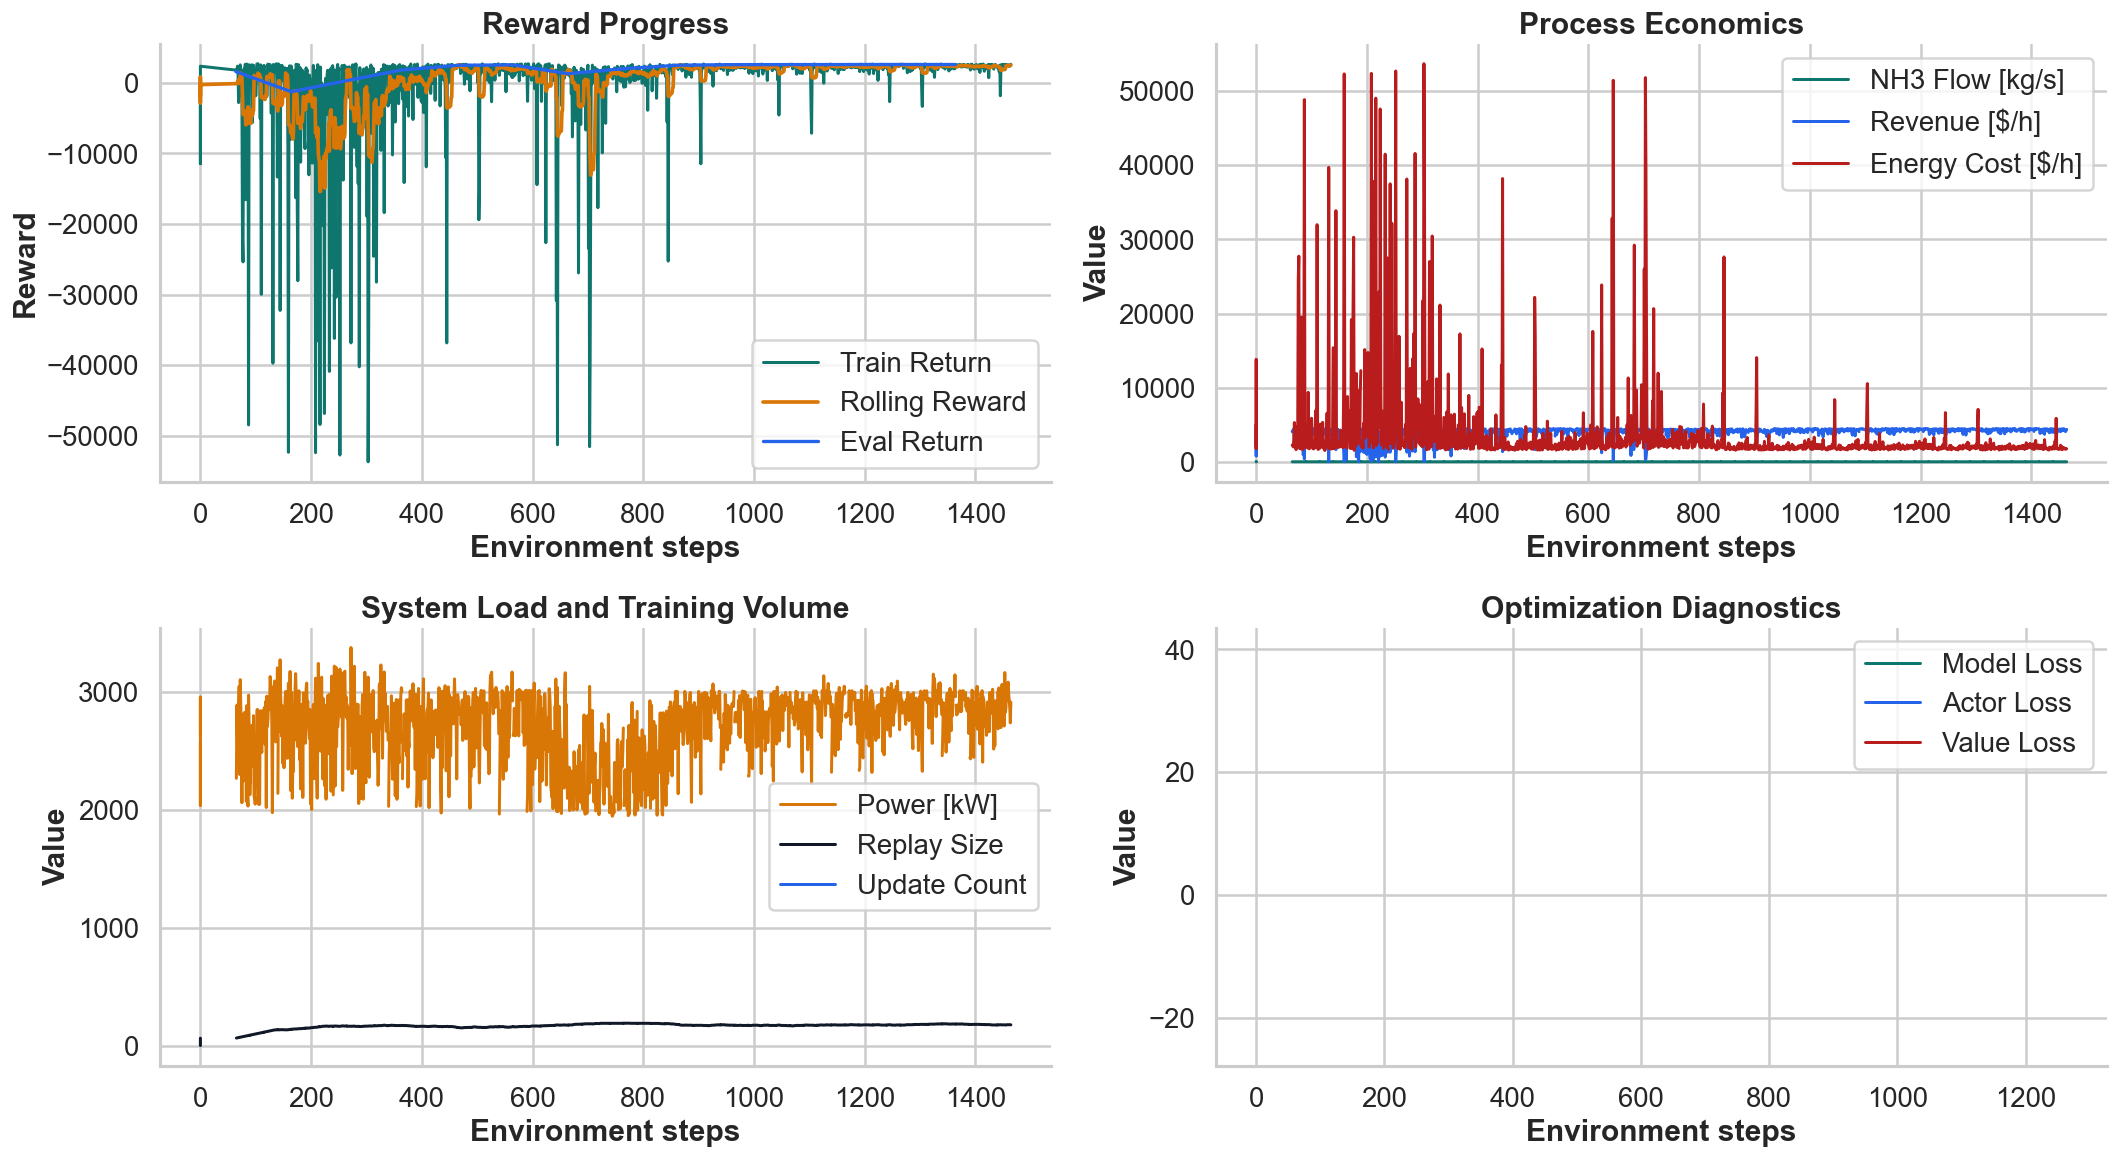

In [8]:
analysis_metrics, analysis_train, analysis_eval = load_train_metrics(RUN_LOGDIR)
analysis_train_summary, analysis_train = summarize_target_progress(analysis_train, TARGET_REWARD, CONVERGENCE_WINDOW)
analysis_eval_summary, analysis_eval = summarize_eval_progress(analysis_eval, TARGET_REWARD, EVAL_STABILITY_WINDOW)

phase_lookup = {spec['name']: spec for spec in PHASE_SPECS}
analysis_phase_name = LAST_PHASE_NAME if LAST_PHASE_NAME is not None else PHASE_SPECS[-1]['name']
analysis_cfg = build_phase_config(BASE_CFG, phase_lookup[analysis_phase_name], reset_existing_run=False)
replay_inventory, replay_selected = summarize_replay_selection(RUN_LOGDIR, analysis_cfg, TARGET_REWARD)

summary_frame = pd.DataFrame([
    {
        'logdir': str(RUN_LOGDIR),
        'analysis_phase': analysis_phase_name,
        'target_reward': TARGET_REWARD,
        'best_train_reward': float(analysis_train_summary['best_train_reward']),
        'rolling_mean': float(analysis_train_summary['rolling_mean']),
        'best_eval_return': float(analysis_eval_summary['best_eval_return']),
        'best_eval_gap': float(analysis_eval_summary['best_eval_gap']),
        'latest_eval_return': float(analysis_eval_summary['latest_eval_return']),
        'mean_last_eval': float(analysis_eval_summary['mean_last_eval']),
        'stable_eval_target': bool(analysis_eval_summary['stable_eval_target']),
        'selected_replay_rows': int(len(replay_selected)),
        'selected_replay_target_hits': int(replay_selected['meets_target'].fillna(False).sum()) if not replay_selected.empty else 0,
    }
])
display(summary_frame)

if phase_history:
    display(pd.DataFrame(phase_history))

if not analysis_eval.empty:
    display(analysis_eval.tail(EVAL_STABILITY_WINDOW)[['step', 'eval_return', 'tail_mean', 'target_hit']])
if not analysis_train.empty:
    display(analysis_train.tail(CONVERGENCE_WINDOW)[['step', 'train_return', 'rolling_mean', 'rolling_hit_rate']])
if not replay_selected.empty:
    display(replay_selected.head(20))

hb.plot_training_diagnostics(analysis_metrics)

In [9]:
comparison_runs = {
    'close_gap_schedule': RUN_LOGDIR,
    'target95_elite_replay': WORKSPACE_DIR / 'runs' / 'dreamerv3_haber_bosch_target95_elite_replay',
    'bo_seeded': WORKSPACE_DIR / 'runs' / 'dreamerv3_haber_bosch_bo_seeded',
    'vanilla': WORKSPACE_DIR / 'runs' / 'dreamerv3_haber_bosch',
}

comparison_rows = []
for label, logdir in comparison_runs.items():
    row = compare_run_to_target(logdir, TARGET_REWARD)
    row['label'] = label
    comparison_rows.append(row)

comparison_frame = pd.DataFrame(comparison_rows)
comparison_frame = comparison_frame.loc[comparison_frame['status'] == 'ok'].copy()
if not comparison_frame.empty:
    comparison_frame = comparison_frame.sort_values(['best_eval_return', 'rolling_mean'], ascending=[False, False]).reset_index(drop=True)
display(comparison_frame)

,logdir,status,episodes,best_train_reward,rolling_mean,best_eval_return,latest_eval_return,mean_last_eval,best_eval_gap,stable_eval_target,label
0,/Users/campatzis/Documents/Research/runs/dream...,ok,1464,2712.623779,2261.295271,2600.450732,2595.043750,2596.140023,57.948025,False,close_gap_schedule
1,/Users/campatzis/Documents/Research/runs/dream...,ok,1664,2711.016846,2351.456950,2582.192773,2572.953125,2554.366976,76.205984,False,target95_elite_replay
2,/Users/campatzis/Documents/Research/runs/dream...,ok,2776,2711.665771,2493.899492,2509.461133,2509.347314,2509.378792,148.937624,False,bo_seeded
3,/Users/campatzis/Documents/Research/runs/dream...,ok,2264,2711.665771,2483.445229,2508.802588,2508.802588,2508.765104,149.596169,False,vanilla


## Readout

Judge the run with four questions:

1. Did the best eval reward reach or exceed the 95% BO target?
2. Did the last few eval checkpoints average at or above the target, or was the best result still a one-off spike?
3. Did the exploit and squeeze phases reduce the training-policy noise enough to keep weak recent episodes out of replay?
4. Does this new schedule materially outperform the earlier target95 elite-replay run on best eval and last-eval mean?